In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = os.path.abspath('..')
sys.path.append(PROJECT_ROOT)
import codes.three_bit_repitition as tc
import codes.nine_bit_repitition as nc

In [2]:
code = nc.NineQubitRepititionCode(seed=42)
res = code.run(
    rounds=20,
    shots=2000,
    px=0.04,
    pz=0.00,
    pm=0.00
)
print(res)

0.2245


In [3]:
er = {}
three_code = tc.ThreeQubitRepititionCode(seed=42, verbose=False)
for prob in range(1, 50):
    px = prob/100
    res = three_code.run(
        rounds=1,
        shots=4000,
        px=px,
        pm=0.00
    )
    er[px] = res

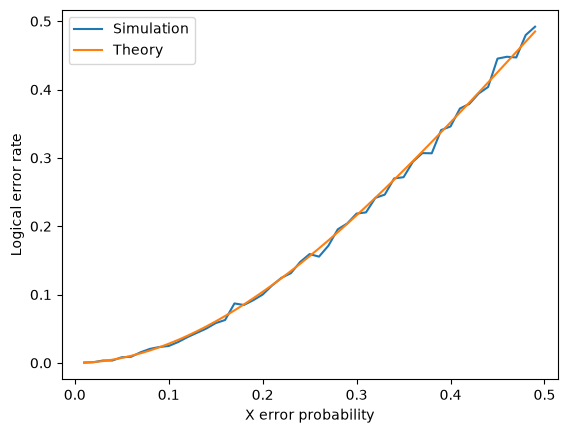

In [4]:
theory = [(3*(p/100)**2) - (2*(p/100)**3) for p in range(1, 50)]
plt.figure()
plt.plot(er.keys(), er.values(), label='Simulation')
plt.plot(er.keys(), theory, label='Theory')
plt.xlabel('X error probability')
plt.ylabel('Logical error rate')
plt.legend()
plt.show()

In [5]:
er = {}
m_error_res = 10
p_error_res = 50
three_code = tc.ThreeQubitRepititionCode(seed=42, verbose=False)
for m_error in range(m_error_res):
    pm = m_error/(20 * m_error_res)
    erx = {}
    for p_error in range(1, p_error_res):
        px = p_error/(2 * p_error_res)
        res = three_code.run(
            rounds=20,
            shots=1000,
            px=px,
            pm=pm
        )

        erx[px] = res
        
    er[pm] = erx

{0.0: {0.01: 0.007, 0.02: 0.022, 0.03: 0.043, 0.04: 0.082, 0.05: 0.13, 0.06: 0.159, 0.07: 0.208, 0.08: 0.265, 0.09: 0.32, 0.1: 0.331, 0.11: 0.368, 0.12: 0.391, 0.13: 0.446, 0.14: 0.453, 0.15: 0.462, 0.16: 0.471, 0.17: 0.479, 0.18: 0.5, 0.19: 0.498, 0.2: 0.494, 0.21: 0.511, 0.22: 0.519, 0.23: 0.496, 0.24: 0.467, 0.25: 0.485, 0.26: 0.486, 0.27: 0.51, 0.28: 0.489, 0.29: 0.488, 0.3: 0.515, 0.31: 0.495, 0.32: 0.476, 0.33: 0.515, 0.34: 0.485, 0.35: 0.493, 0.36: 0.476, 0.37: 0.507, 0.38: 0.489, 0.39: 0.52, 0.4: 0.492, 0.41: 0.498, 0.42: 0.505, 0.43: 0.494, 0.44: 0.503, 0.45: 0.539, 0.46: 0.524, 0.47: 0.51, 0.48: 0.497, 0.49: 0.528}, 0.005: {0.01: 0.021, 0.02: 0.045, 0.03: 0.076, 0.04: 0.109, 0.05: 0.138, 0.06: 0.215, 0.07: 0.266, 0.08: 0.285, 0.09: 0.341, 0.1: 0.366, 0.11: 0.394, 0.12: 0.435, 0.13: 0.447, 0.14: 0.454, 0.15: 0.475, 0.16: 0.461, 0.17: 0.485, 0.18: 0.502, 0.19: 0.517, 0.2: 0.502, 0.21: 0.497, 0.22: 0.517, 0.23: 0.509, 0.24: 0.525, 0.25: 0.518, 0.26: 0.507, 0.27: 0.489, 0.28: 0.5

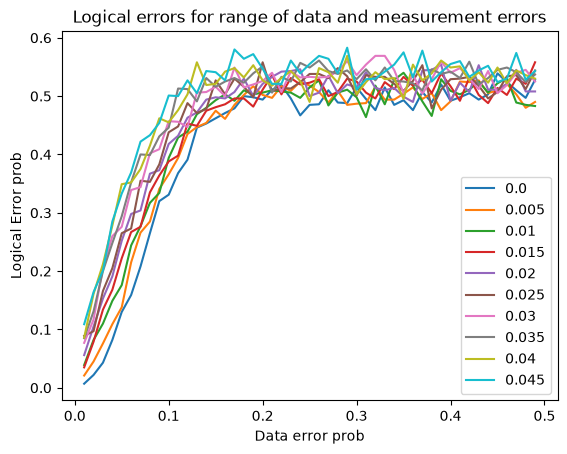

In [6]:
print(er)
plt.figure()
for k, v in er.items():
    plt.plot(v.keys(), v.values(), label=k)
    plt.xlabel('Data error prob')
    # both logical error and non-codestates
    plt.ylabel('Logical Error prob')
    plt.title('Logical errors for range of data and measurement errors')
plt.legend()

# plt.show()

In [14]:
plt.savefig('../../figs/rep3_px.png')

<Figure size 640x480 with 0 Axes>